# 03 – Sentiment Analysis Using Natural Language Processing

## 1. Introduction

Sentiment analysis is a Natural Language Processing (NLP) technique used to identify the emotional tone expressed in textual data.

In this project, sentiment analysis is performed on customer reviews to understand customer opinions and satisfaction levels regarding products.

The VADER (Valence Aware Dictionary and sEntiment Reasoner) sentiment analysis tool is used to calculate sentiment scores and classify customer reviews into Positive, Negative, and Neutral categories.

## 2. Objectives

1. Load the cleaned customer reviews dataset.
2. Understand the concept of sentiment analysis.
3. Apply the VADER sentiment analyzer to customer reviews.
4. Calculate compound sentiment scores.
5. Classify reviews into Positive, Negative, and Neutral categories.
6. Analyze the distribution of customer sentiments.
7. Compare sentiment results with customer ratings.

## 3. Technology Used

- Python
- Pandas
- Matplotlib
- Seaborn
- NLTK
- VADER Sentiment Analyzer

## 4. Expected Outcome

A sentiment-annotated customer reviews dataset containing sentiment scores and sentiment labels for further customer intelligence analysis.

In [3]:
# Install required NLP library

%pip install nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [5]:
# Download VADER sentiment lexicon

nltk.download("vader_lexicon")

print("VADER lexicon downloaded successfully!")

VADER lexicon downloaded successfully!


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\anant\AppData\Roaming\nltk_data...


## 5. Loading the Cleaned Dataset

The cleaned customer reviews dataset generated during the data cleaning stage is loaded into this notebook.

The preprocessed review text will be used as input for sentiment analysis. The original ratings and review dates will also be retained for further comparison and analysis.

In [6]:
# Set project directory and load cleaned dataset

from pathlib import Path

current_path = Path.cwd()
PROJECT_ROOT = None

for path in [current_path, *current_path.parents]:
    if (path / "data").is_dir() and (path / "notebooks").is_dir():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project folder not found.")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

CLEANED_DATASET_PATH = (
    PROCESSED_DIR / "cleaned_customer_reviews.csv"
)

sentiment_df = pd.read_csv(
    CLEANED_DATASET_PATH,
    low_memory=False
)

print("Cleaned dataset loaded successfully!")
print("Dataset Shape:", sentiment_df.shape)

display(
    sentiment_df[
        ["reviews.text", "review_text_clean", "reviews.rating"]
    ].head()
)

Cleaned dataset loaded successfully!
Dataset Shape: (28332, 24)


,reviews.text,review_text_clean,reviews.rating
0,I order 3 of them and one of the item is bad q...,i order 3 of them and one of the item is bad q...,3
1,Bulk is always the less expensive way to go fo...,bulk is always the less expensive way to go fo...,4
2,Well they are not Duracell but for the price i...,well they are not duracell but for the price i...,5
3,Seem to work as well as name brand batteries a...,seem to work as well as name brand batteries a...,5
4,These batteries are very long lasting the pric...,these batteries are very long lasting the pric...,5


## 6. Initializing the VADER Sentiment Analyzer

VADER (Valence Aware Dictionary and sEntiment Reasoner) is a lexicon and rule-based sentiment analysis tool available in the NLTK library.

It is specifically designed to analyze sentiment in textual content. VADER considers positive and negative words, punctuation, capitalization, and other linguistic features to calculate sentiment scores.

In this project, VADER is used to analyze customer reviews and determine their overall sentiment.

In [7]:
# Initialize VADER Sentiment Analyzer

from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

print("VADER Sentiment Analyzer initialized successfully!")

VADER Sentiment Analyzer initialized successfully!


## 7. Understanding Sentiment Scores

VADER generates four sentiment scores for each review:

1. Positive: Measures the intensity of positive sentiment.
2. Negative: Measures the intensity of negative sentiment.
3. Neutral: Measures the intensity of neutral sentiment.
4. Compound: Represents the overall normalized sentiment score ranging from -1 to +1.

The compound score is used to classify customer reviews into three sentiment categories:

- Positive: Compound score greater than or equal to 0.05.
- Negative: Compound score less than or equal to -0.05.
- Neutral: Compound score between -0.05 and +0.05.

In [8]:
# Test VADER on sample customer reviews

sample_reviews = [
    "This product is amazing and I absolutely love it!",
    "Very poor quality. I am extremely disappointed.",
    "The product is okay and works as expected."
]

for review in sample_reviews:

    scores = sia.polarity_scores(review)

    print("Review:", review)
    print("Sentiment Scores:", scores)
    print("Compound Score:", scores["compound"])
    print("-" * 70)

Review: This product is amazing and I absolutely love it!
Sentiment Scores: {'neg': 0.0, 'neu': 0.411, 'pos': 0.589, 'compound': 0.862}
Compound Score: 0.862
----------------------------------------------------------------------
Review: Very poor quality. I am extremely disappointed.
Sentiment Scores: {'neg': 0.629, 'neu': 0.371, 'pos': 0.0, 'compound': -0.7774}
Compound Score: -0.7774
----------------------------------------------------------------------
Review: The product is okay and works as expected.
Sentiment Scores: {'neg': 0.0, 'neu': 0.787, 'pos': 0.213, 'compound': 0.2263}
Compound Score: 0.2263
----------------------------------------------------------------------


## 8. Performing Sentiment Analysis on Customer Reviews

VADER sentiment analysis is applied to all cleaned customer reviews to calculate their negative, neutral, positive, and compound sentiment scores.

The compound score represents the overall sentiment polarity of each review and is used in the next step to classify customer feedback into positive, negative, and neutral categories.

In [8]:
# Initialize VADER Sentiment Analyzer
import nltk
nltk.download("vader_lexicon")

from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

# Calculate sentiment scores for all reviews
sentiment_scores = sentiment_df["review_text_clean"].apply(
    sia.polarity_scores
)

# Store sentiment scores
sentiment_df["vader_negative"] = sentiment_scores.apply(lambda x: x["neg"])
sentiment_df["vader_neutral"] = sentiment_scores.apply(lambda x: x["neu"])
sentiment_df["vader_positive"] = sentiment_scores.apply(lambda x: x["pos"])
sentiment_df["sentiment_score"] = sentiment_scores.apply(lambda x: x["compound"])

print("Sentiment analysis completed successfully!")
print("Total Reviews Analyzed:", len(sentiment_df))

display(sentiment_df[[
    "review_text_clean",
    "vader_negative",
    "vader_neutral",
    "vader_positive",
    "sentiment_score"
]].head(10))

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\anant\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Sentiment analysis completed successfully!
Total Reviews Analyzed: 28332


,review_text_clean,vader_negative,vader_neutral,vader_positive,sentiment_score
0,i order 3 of them and one of the item is bad q...,0.186,0.814,0.000,-0.6908
1,bulk is always the less expensive way to go fo...,0.000,0.828,0.172,0.3612
2,well they are not duracell but for the price i...,0.000,0.577,0.423,0.7650
3,seem to work as well as name brand batteries a...,0.000,0.688,0.312,0.6124
4,these batteries are very long lasting the pric...,0.000,0.687,0.313,0.6249
5,bought a lot of batteries for christmas and th...,0.000,0.791,0.209,0.8625
6,ive not had any problame with these batteries ...,0.000,0.834,0.166,0.4927
7,well if you are looking for cheap non-recharge...,0.000,0.766,0.234,0.7003
8,these do not hold the amount of high power jui...,0.000,0.826,0.174,0.4215
9,amazonbasics aa aaa batteries have done well b...,0.000,0.773,0.227,0.6124


## 9. Sentiment Classification

Based on the VADER compound score, each customer review is classified into one of three sentiment categories.

The following classification thresholds are applied:

- Positive: Compound score greater than or equal to 0.05.
- Negative: Compound score less than or equal to -0.05.
- Neutral: Compound score greater than -0.05 and less than 0.05.

The resulting sentiment labels are stored in a new column named `sentiment_label`.

In [9]:
# Classify customer reviews based on compound sentiment score

def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"


# Apply sentiment classification
sentiment_df["sentiment_label"] = (
    sentiment_df["sentiment_score"].apply(classify_sentiment)
)

print("Sentiment classification completed successfully!")

# Display classified reviews
display(
    sentiment_df[
        ["reviews.text", "sentiment_score", "sentiment_label"]
    ].head(10)
)

Sentiment classification completed successfully!


,reviews.text,sentiment_score,sentiment_label
0,I order 3 of them and one of the item is bad q...,-0.6908,Negative
1,Bulk is always the less expensive way to go fo...,0.3612,Positive
2,Well they are not Duracell but for the price i...,0.7650,Positive
3,Seem to work as well as name brand batteries a...,0.6124,Positive
4,These batteries are very long lasting the pric...,0.6249,Positive
5,Bought a lot of batteries for Christmas and th...,0.8625,Positive
6,ive not had any problame with these batteries ...,0.4927,Positive
7,Well if you are looking for cheap non-recharge...,0.7003,Positive
8,These do not hold the amount of high power jui...,0.4215,Positive
9,AmazonBasics AA AAA batteries have done well b...,0.6124,Positive


## 10. Sentiment Distribution Analysis

After classifying customer reviews, the distribution of positive, negative, and neutral sentiments is analysed.

The total number and percentage of reviews belonging to each sentiment category are calculated to understand the overall customer perception of the products.

This analysis helps identify the proportion of satisfied and dissatisfied customers and provides an overview of customer sentiment across the dataset.

In [11]:
# Calculate the number of reviews in each sentiment category

sentiment_counts = sentiment_df["sentiment_label"].value_counts()

# Calculate the percentage of each sentiment category

sentiment_percentages = (
    sentiment_df["sentiment_label"].value_counts(normalize=True) * 100
)

# Create a sentiment summary DataFrame

sentiment_summary = pd.DataFrame({
    "Number of Reviews": sentiment_counts,
    "Percentage": sentiment_percentages
})

# Arrange sentiment categories in a fixed order

sentiment_summary = sentiment_summary.reindex(
    ["Positive", "Neutral", "Negative"],
    fill_value=0
)

# Display sentiment distribution

display(sentiment_summary.round(2))

print("Total Reviews:", sentiment_summary["Number of Reviews"].sum())

,Number of Reviews,Percentage
sentiment_label,,
Positive,23724,83.74
Neutral,2498,8.82
Negative,2110,7.45


Total Reviews: 28332


## 11. Interpretation of Sentiment Analysis Results

The sentiment distribution analysis provides an overview of customer opinions based on 28,332 product reviews.

The results indicate that:

- **Positive Sentiment:** 23,724 reviews (83.74%) express positive opinions, indicating that most customers have a favourable perception of the products.
- **Neutral Sentiment:** 2,498 reviews (8.82%) contain neutral opinions or relatively balanced language.
- **Negative Sentiment:** 2,110 reviews (7.45%) express dissatisfaction, highlighting areas that may require improvement.

Overall, the dataset shows a predominantly positive customer sentiment. However, negative feedback should also be examined to identify recurring product-related issues and opportunities for improvement.

These findings provide a foundation for further theme analysis and business decision-making.

## 12. Sentiment Distribution Visualization

A graphical representation of the sentiment distribution is created to provide a clear comparison of positive, neutral, and negative customer reviews.

A bar chart is used to visualize the number of reviews in each sentiment category. This visualization makes it easier to identify the dominant sentiment and understand the overall distribution of customer opinions.

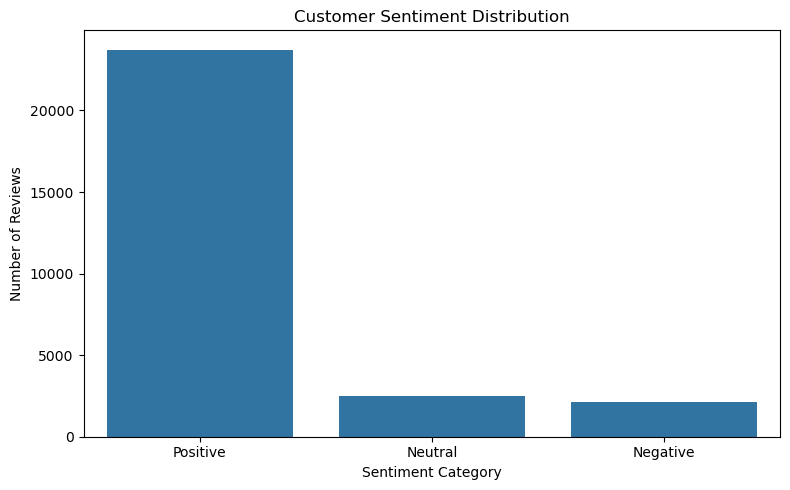

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_summary.index,
    y=sentiment_summary["Number of Reviews"]
)

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

## 13. Rating vs Sentiment Analysis

In this step, customer star ratings are compared with the sentiment labels generated using the VADER sentiment analysis technique.

The comparison helps understand the relationship between customer ratings and the actual sentiment expressed in their written reviews.

A cross-tabulation table is created to examine how positive, neutral, and negative sentiments are distributed across different rating levels (1 to 5 stars).

This analysis helps identify differences between numerical customer ratings and text-based customer opinions.

In [13]:
# Compare customer ratings with sentiment categories

rating_sentiment = pd.crosstab(
    sentiment_df["reviews.rating"],
    sentiment_df["sentiment_label"]
)

# Arrange sentiment columns
rating_sentiment = rating_sentiment.reindex(
    columns=["Positive", "Neutral", "Negative"],
    fill_value=0
)

print("Customer Rating vs Sentiment Analysis")

display(rating_sentiment)

print("Total Reviews:", rating_sentiment.values.sum())

Customer Rating vs Sentiment Analysis


sentiment_label,Positive,Neutral,Negative
reviews.rating,,,
1,254,164,547
2,221,140,255
3,718,230,258
4,4849,429,370
5,17682,1535,680


Total Reviews: 28332


## 14. Rating vs Sentiment Visualization

A heatmap is created to visualize the relationship between customer star ratings and VADER-based sentiment categories.

The percentage distribution of sentiments is calculated separately for each rating level. This row-wise percentage comparison helps identify how customer sentiment changes across different star ratings.

The heatmap provides a visual understanding of the relationship between numerical ratings and text-based customer opinions.

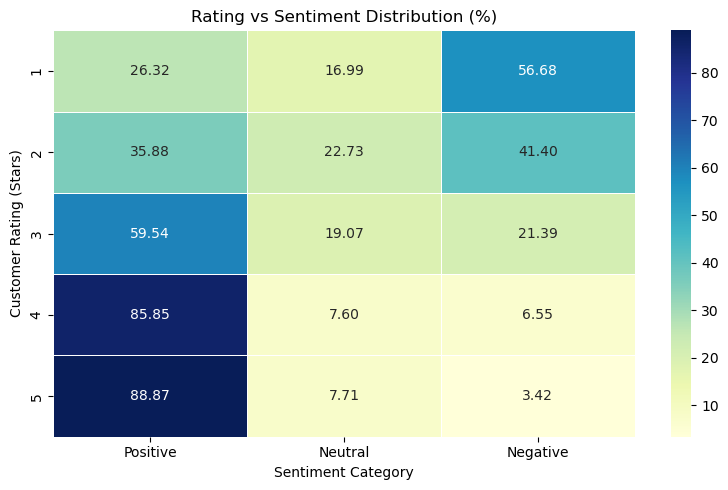

In [15]:
# Calculate row-wise sentiment percentages

rating_sentiment_percent = pd.crosstab(
    sentiment_df["reviews.rating"],
    sentiment_df["sentiment_label"],
    normalize="index"
) * 100

# Arrange sentiment columns
rating_sentiment_percent = rating_sentiment_percent.reindex(
    columns=["Positive", "Neutral", "Negative"],
    fill_value=0
)

# Create heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    rating_sentiment_percent,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Rating vs Sentiment Distribution (%)")
plt.xlabel("Sentiment Category")
plt.ylabel("Customer Rating (Stars)")

plt.tight_layout()
plt.show()

## 15. Interpretation of Rating vs Sentiment Analysis

The heatmap illustrates the relationship between customer star ratings and sentiment categories generated using VADER.

The following observations can be made:

- **1-Star Ratings:** 56.68% of reviews are negative, indicating a high level of customer dissatisfaction.
- **2-Star Ratings:** 41.40% of reviews are negative, showing that many customers have expressed dissatisfaction.
- **3-Star Ratings:** 59.54% of reviews are positive, suggesting that some average-rated products contain favourable review language.
- **4-Star Ratings:** 85.85% of reviews are positive, indicating generally favourable customer opinions.
- **5-Star Ratings:** 88.87% of reviews are positive, representing strong customer satisfaction.

Overall, the analysis shows that higher customer ratings generally correspond to more positive review sentiment. However, differences between star ratings and text-based sentiment may occur because VADER analyses the language used in reviews rather than the numerical rating.

These findings can help businesses identify dissatisfied customers and investigate the reasons behind negative feedback.

## 16. Exporting Sentiment Analysis Results

After completing sentiment analysis and classification, the processed dataset is exported as a CSV file.

The exported dataset contains the original customer review information, cleaned review text, VADER sentiment scores, and sentiment labels.

This file will be used in the next stage of the project for customer feedback theme analysis.

In [16]:
# Define output file path

OUTPUT_PATH = PROCESSED_DIR / "sentiment_analysis_results.csv"

# Export sentiment analysis results
sentiment_df.to_csv(OUTPUT_PATH, index=False)

print("Sentiment analysis results exported successfully!")
print("File Location:", OUTPUT_PATH)
print("Total Records Exported:", len(sentiment_df))

Sentiment analysis results exported successfully!
File Location: C:\Users\anant\OneDrive\Desktop\AI_Customer_Intelligence\data\processed\sentiment_analysis_results.csv
Total Records Exported: 28332


## 17. Final Dataset Verification

The exported sentiment analysis dataset is reloaded to verify successful file creation and data integrity.

The total number of records, sentiment-related columns, and dataset dimensions are checked to ensure that all sentiment analysis results have been saved correctly.

In [17]:
# Reload exported dataset
verified_df = pd.read_csv(OUTPUT_PATH, low_memory=False)

# Verify dataset
print("Final Dataset Shape:", verified_df.shape)
print("Total Records:", len(verified_df))

print("\nSentiment Distribution:")
display(verified_df["sentiment_label"].value_counts())

print("\nRequired Columns Verification:")

required_columns = [
    "review_text_clean",
    "vader_negative",
    "vader_neutral",
    "vader_positive",
    "sentiment_score",
    "sentiment_label"
]

for column in required_columns:
    print(column, ":", column in verified_df.columns)

Final Dataset Shape: (28332, 29)
Total Records: 28332

Sentiment Distribution:


sentiment_label
Positive    23724
Neutral      2498
Negative     2110
Name: count, dtype: int64


Required Columns Verification:
review_text_clean : True
vader_negative : True
vader_neutral : True
vader_positive : True
sentiment_score : True
sentiment_label : True
